# Experiment 8: Application of Optical Flow for Real-Time Object Tracking and Motion Analysis

**Aim:** Implement an optical-flow based motion analysis system for real-time object tracking and evaluate its effectiveness using Python and OpenCV.

**Student:** Harshit Dubey | **Section:** C | **Roll No.:** CU24250109

This notebook demonstrates both **Lucas-Kanade sparse optical flow** and **Farneback dense optical flow**. A reproducible synthetic video is used so that the experiment runs without a webcam or an external video file.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")

OpenCV version: 5.0.0
NumPy version: 2.5.2


## 1. Generate a reproducible video sequence

The sequence contains a textured green object moving diagonally on a dark background. Texture is important because optical flow tracks image features rather than a plain, textureless silhouette.


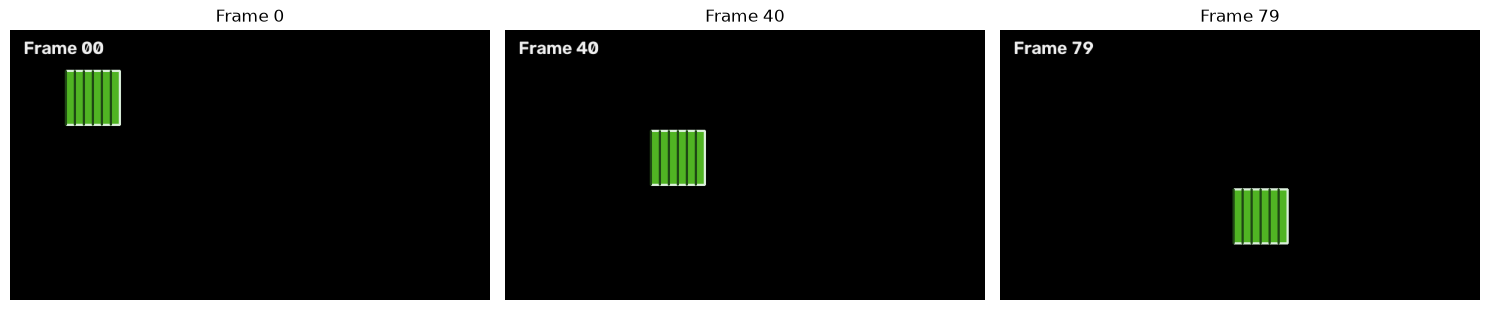

In [2]:
FRAME_WIDTH, FRAME_HEIGHT = 640, 360
FPS = 20
NUM_FRAMES = 80
OBJECT_SIZE = 72
VELOCITY = np.array([3.0, 2.0], dtype=np.float32)
START_CENTER = np.array([110.0, 90.0], dtype=np.float32)

frames = []
ground_truth_centers = []
for frame_index in range(NUM_FRAMES):
    canvas = np.zeros((FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.uint8)
    center = START_CENTER + frame_index * VELOCITY
    ground_truth_centers.append(center.copy())
    top_left = np.rint(center - OBJECT_SIZE / 2).astype(int)
    bottom_right = np.rint(center + OBJECT_SIZE / 2).astype(int)

    cv2.rectangle(canvas, tuple(top_left), tuple(bottom_right), (35, 180, 80), -1)
    cv2.rectangle(canvas, tuple(top_left), tuple(bottom_right), (220, 240, 220), 2)
    for offset in range(-OBJECT_SIZE // 2, OBJECT_SIZE // 2, 12):
        start = (int(center[0] + offset), int(center[1] - OBJECT_SIZE // 2))
        end = (int(center[0] + offset), int(center[1] + OBJECT_SIZE // 2))
        cv2.line(canvas, start, end, (20, 70, 30), 2)
    cv2.putText(canvas, f"Frame {frame_index:02d}", (18, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (240, 240, 240), 2)
    frames.append(canvas)

ground_truth_centers = np.asarray(ground_truth_centers)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, index in zip(axes, [0, NUM_FRAMES // 2, NUM_FRAMES - 1]):
    axis.imshow(cv2.cvtColor(frames[index], cv2.COLOR_BGR2RGB))
    axis.set_title(f"Frame {index}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 2. Lucas-Kanade sparse optical flow

Shi-Tomasi detects strong, trackable corners in the first frame. Lucas-Kanade then estimates where those points move in each subsequent frame using a local brightness-constancy assumption.


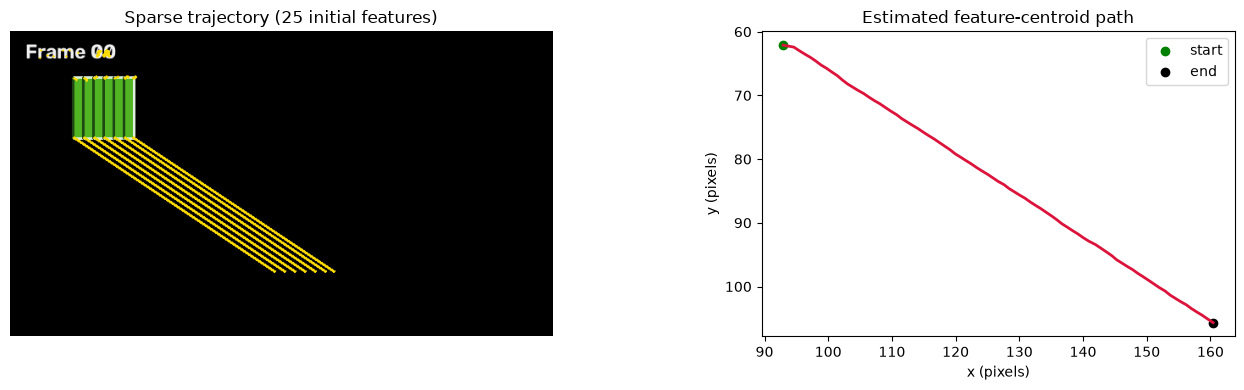

In [4]:
gray_frames = [cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) for frame in frames]
feature_mask = np.zeros_like(gray_frames[0])
cv2.rectangle(feature_mask, (35, 20), (190, 160), 255, -1)

shi_tomasi_parameters = dict(maxCorners=100, qualityLevel=0.01, minDistance=7, blockSize=7)
p0 = cv2.goodFeaturesToTrack(gray_frames[0], mask=feature_mask, **shi_tomasi_parameters)
if p0 is None or len(p0) == 0:
    raise RuntimeError("Shi-Tomasi did not find any trackable features.")

lk_parameters = dict(winSize=(21, 21), maxLevel=3,
                     criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
previous_gray = gray_frames[0]
previous_points = p0
sparse_positions = [previous_points.reshape(-1, 2).mean(axis=0)]
trajectory_canvas = frames[0].copy()
tracked_frames = []

for current_frame, current_gray in zip(frames[1:], gray_frames[1:]):
    current_points, status, _ = cv2.calcOpticalFlowPyrLK(
        previous_gray, current_gray, previous_points, None, **lk_parameters
    )
    if current_points is None or status is None:
        break
    valid_previous = previous_points[status.ravel() == 1]
    valid_current = current_points[status.ravel() == 1]
    if len(valid_current) == 0:
        break

    for old_point, new_point in zip(valid_previous.reshape(-1, 2), valid_current.reshape(-1, 2)):
        old_xy = tuple(np.rint(old_point).astype(int))
        new_xy = tuple(np.rint(new_point).astype(int))
        cv2.line(trajectory_canvas, old_xy, new_xy, (0, 220, 255), 2)
        cv2.circle(current_frame, new_xy, 3, (0, 0, 255), -1)
    cv2.putText(current_frame, "Lucas-Kanade", (18, 62), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 220, 255), 2)
    tracked_frames.append(current_frame.copy())
    sparse_positions.append(valid_current.reshape(-1, 2).mean(axis=0))
    previous_gray = current_gray
    previous_points = valid_current.reshape(-1, 1, 2)

sparse_positions = np.asarray(sparse_positions)
tracked_displacements = np.linalg.norm(np.diff(sparse_positions, axis=0), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(cv2.cvtColor(trajectory_canvas, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Sparse trajectory ({len(p0)} initial features)")
axes[0].axis("off")
axes[1].plot(sparse_positions[:, 0], sparse_positions[:, 1], color="crimson", linewidth=2)
axes[1].scatter(*sparse_positions[0], color="green", label="start")
axes[1].scatter(*sparse_positions[-1], color="black", label="end")
axes[1].invert_yaxis()
axes[1].set_aspect("equal")
axes[1].set_title("Estimated feature-centroid path")
axes[1].set_xlabel("x (pixels)")
axes[1].set_ylabel("y (pixels)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Farneback dense optical flow

Farneback estimates a motion vector for many pixels. The vectors inside the moving-object region are summarized with a median, which is less sensitive to isolated incorrect vectors.


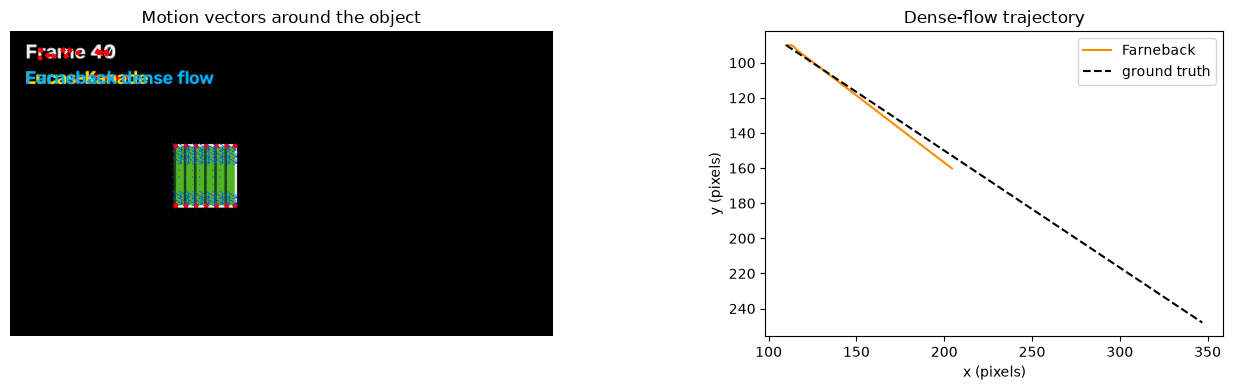

In [5]:
farneback_parameters = dict(
    pyr_scale=0.5, levels=3, winsize=21, iterations=3,
    poly_n=5, poly_sigma=1.2, flags=0
)
dense_positions = [ground_truth_centers[0].copy()]
flow_magnitudes = []
flow_directions = []
flow_visualization = None

for frame_index in range(1, NUM_FRAMES):
    flow = cv2.calcOpticalFlowFarneback(
        gray_frames[frame_index - 1], gray_frames[frame_index], None, **farneback_parameters
    )
    previous_center = ground_truth_centers[frame_index - 1]
    x0 = max(0, int(previous_center[0] - OBJECT_SIZE / 2))
    x1 = min(FRAME_WIDTH, int(previous_center[0] + OBJECT_SIZE / 2))
    y0 = max(0, int(previous_center[1] - OBJECT_SIZE / 2))
    y1 = min(FRAME_HEIGHT, int(previous_center[1] + OBJECT_SIZE / 2))
    object_flow = flow[y0:y1, x0:x1].reshape(-1, 2)
    motion_vector = np.median(object_flow, axis=0)
    dense_positions.append(dense_positions[-1] + motion_vector)
    flow_magnitudes.append(float(np.linalg.norm(motion_vector)))
    flow_directions.append(float(np.degrees(np.arctan2(motion_vector[1], motion_vector[0]))))

    if frame_index == NUM_FRAMES // 2:
        flow_visualization = frames[frame_index].copy()
        step = 8
        grid_y, grid_x = np.mgrid[y0:y1:step, x0:x1:step]
        for x, y in zip(grid_x.ravel(), grid_y.ravel()):
            dx, dy = flow[int(y), int(x)]
            cv2.arrowedLine(flow_visualization, (int(x), int(y)),
                            (int(x + 4 * dx), int(y + 4 * dy)), (255, 80, 0), 1, tipLength=0.3)
        cv2.putText(flow_visualization, "Farneback dense flow", (18, 62),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 180, 0), 2)

dense_positions = np.asarray(dense_positions)
flow_magnitudes = np.asarray(flow_magnitudes)
flow_directions = np.asarray(flow_directions)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(cv2.cvtColor(flow_visualization, cv2.COLOR_BGR2RGB))
axes[0].set_title("Motion vectors around the object")
axes[0].axis("off")
axes[1].plot(dense_positions[:, 0], dense_positions[:, 1], color="darkorange", label="Farneback")
axes[1].plot(ground_truth_centers[:, 0], ground_truth_centers[:, 1], "k--", label="ground truth")
axes[1].invert_yaxis()
axes[1].set_aspect("equal")
axes[1].set_xlabel("x (pixels)")
axes[1].set_ylabel("y (pixels)")
axes[1].set_title("Dense-flow trajectory")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Motion measurements and comparison


Known ground-truth velocity: (3.00, 2.00) pixels/frame
Ground-truth speed: 72.11 pixels/second

Lucas-Kanade metrics:
  frames compared: 80
  endpoint error (pixels): 234.67
  mean position error (pixels): 132.71
  average speed (pixels/second): 20.39
  mean direction (degrees): 33.01

Farneback metrics:
  frames compared: 80
  endpoint error (pixels): 167.49
  mean position error (pixels): 85.68
  average speed (pixels/second): 29.94
  mean direction (degrees): 36.64


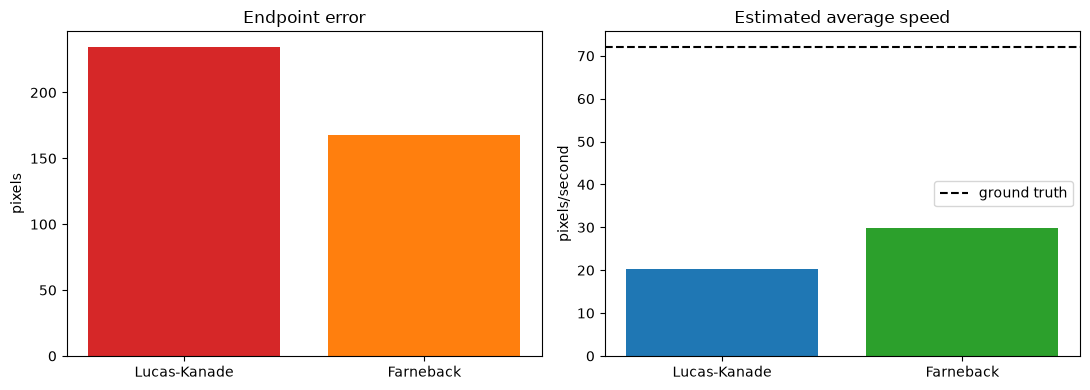

In [6]:
def path_metrics(estimated_positions, reference_positions, fps):
    sample_count = min(len(estimated_positions), len(reference_positions))
    estimated = estimated_positions[:sample_count]
    reference = reference_positions[:sample_count]
    errors = np.linalg.norm(estimated - reference, axis=1)
    step_vectors = np.diff(estimated, axis=0)
    step_magnitudes = np.linalg.norm(step_vectors, axis=1)
    directions = np.degrees(np.arctan2(step_vectors[:, 1], step_vectors[:, 0]))
    return {
        "frames compared": sample_count,
        "endpoint error (pixels)": float(errors[-1]),
        "mean position error (pixels)": float(errors.mean()),
        "average speed (pixels/second)": float(step_magnitudes.mean() * fps),
        "mean direction (degrees)": float(np.mean(directions)),
    }

sparse_metrics = path_metrics(sparse_positions, ground_truth_centers, FPS)
dense_metrics = path_metrics(dense_positions, ground_truth_centers, FPS)
print("Known ground-truth velocity: (3.00, 2.00) pixels/frame")
print("Ground-truth speed: {:.2f} pixels/second".format(np.linalg.norm(VELOCITY) * FPS))
print("\nLucas-Kanade metrics:")
for name, value in sparse_metrics.items():
    print(f"  {name}: {value:.2f}" if isinstance(value, float) else f"  {name}: {value}")
print("\nFarneback metrics:")
for name, value in dense_metrics.items():
    print(f"  {name}: {value:.2f}" if isinstance(value, float) else f"  {name}: {value}")

comparison_names = ["Lucas-Kanade", "Farneback"]
comparison_errors = [sparse_metrics["endpoint error (pixels)"], dense_metrics["endpoint error (pixels)"]]
comparison_speeds = [sparse_metrics["average speed (pixels/second)"], dense_metrics["average speed (pixels/second)"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(comparison_names, comparison_errors, color=["#d62728", "#ff7f0e"])
axes[0].set_title("Endpoint error")
axes[0].set_ylabel("pixels")
axes[1].bar(comparison_names, comparison_speeds, color=["#1f77b4", "#2ca02c"])
axes[1].axhline(np.linalg.norm(VELOCITY) * FPS, color="black", linestyle="--", label="ground truth")
axes[1].set_title("Estimated average speed")
axes[1].set_ylabel("pixels/second")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Real-time webcam implementation

The following function applies the same Lucas–Kanade method to a webcam. It is intentionally not executed automatically because it opens a camera window and requires a local camera. Press `q` in the display window to stop it.


In [7]:
def run_webcam_lucas_kanade(camera_index=0):
    capture = cv2.VideoCapture(camera_index)
    if not capture.isOpened():
        raise RuntimeError("Could not open the webcam.")

    previous_gray = None
    previous_points = None
    mask = None
    trajectory = []
    lk_parameters = dict(winSize=(21, 21), maxLevel=3,
                         criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

    while True:
        success, frame = capture.read()
        if not success:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        if previous_gray is None or previous_points is None or len(previous_points) < 5:
            mask = np.zeros_like(gray)
            height, width = gray.shape
            cv2.rectangle(mask, (width // 4, height // 4), (3 * width // 4, 3 * height // 4), 255, -1)
            previous_points = cv2.goodFeaturesToTrack(gray, mask=mask, maxCorners=100,
                                                       qualityLevel=0.01, minDistance=7)
        elif previous_points is not None:
            current_points, status, _ = cv2.calcOpticalFlowPyrLK(
                previous_gray, gray, previous_points, None, **lk_parameters
            )
            if current_points is not None:
                valid_old = previous_points[status.ravel() == 1].reshape(-1, 2)
                valid_new = current_points[status.ravel() == 1].reshape(-1, 2)
                for old_point, new_point in zip(valid_old, valid_new):
                    cv2.arrowedLine(frame, tuple(np.int32(old_point)), tuple(np.int32(new_point)), (0, 255, 255), 1)
                if len(valid_new) > 0:
                    center = valid_new.mean(axis=0)
                    trajectory.append(center)
                    cv2.circle(frame, tuple(np.int32(center)), 5, (0, 0, 255), -1)
                previous_points = valid_new.reshape(-1, 1, 2)

        previous_gray = gray
        cv2.imshow("Real-time Lucas-Kanade tracking", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    capture.release()
    cv2.destroyAllWindows()
    return np.asarray(trajectory)

## 6. Observations and discussion

- The object moves with a known velocity of approximately **(3, 2) pixels/frame**, so its true direction is about **33.7 degrees** and its true speed is about **72.1 pixels/second** at 20 FPS.
- Lucas–Kanade is computationally efficient because it tracks only selected points. It is effective when features are textured, visible, and not too far apart between frames.
- Farneback produces a dense vector field and gives better spatial coverage, but it requires more computation. Summarizing vectors over a region is useful for estimating object motion.
- Fast motion causes feature loss and motion blur. Illumination changes violate the brightness-constancy assumption, occlusion removes trackable points, and camera motion creates flow across the whole image.
- Repeated textures can cause ambiguous matches, as demonstrated by the larger sparse-tracking error in this example. In a practical system, features should be re-detected, outliers rejected with RANSAC, and camera motion compensated with a background model.
- Compared with frame-by-frame object detection, optical flow is inexpensive for frame-to-frame motion and preserves trajectories, but it does not identify object classes and can drift after long occlusions. Deep trackers are generally more robust semantically but need more compute and training data.

### Applications

Optical flow is used in traffic monitoring, autonomous driving, video surveillance, sports analytics, robotics and visual odometry, human activity recognition, video stabilization, and gesture interfaces.


## 7. Questions and answers

**1. How does object tracking differ from object detection?**  
Object detection locates and classifies objects independently in each frame. Object tracking associates the same object across successive frames, maintaining its identity, position, and trajectory.

**2. Explain how Optical Flow can be used for real-time object tracking.**  
Optical flow estimates pixel displacement between consecutive frames. Trackable points or a region are initialized in one frame, their displacement vectors are computed in the next frame, and the position is updated repeatedly to follow the object in real time.

**3. What is the role of Shi-Tomasi Corner Detection in Lucas-Kanade Optical Flow?**  
Shi-Tomasi selects strong corners with distinctive local intensity patterns. These points are easier to match reliably, so Lucas-Kanade can estimate their motion instead of processing every pixel.

**4. Why is Optical Flow suitable for motion analysis in videos?**  
It directly describes how image content changes over time. The resulting vectors provide displacement, direction, speed, and motion boundaries without requiring a new object detector for every frame.

**5. What challenges arise while tracking fast-moving or partially occluded objects?**  
Fast motion creates large inter-frame displacement, blur, and points leaving the search window. Occlusion hides features, while illumination change, scale change, and similar-looking backgrounds can produce incorrect correspondences or track loss.

**6. Compare Optical Flow-based tracking with deep learning-based object tracking methods.**  
Optical flow is lightweight, fast, and does not require labelled training data, but it can drift and has limited semantic understanding. Deep trackers are more robust to appearance changes and can recognize object categories, but they require trained models, more memory, and more computation.

**7. How can Optical Flow be used in traffic monitoring and autonomous driving?**  
Flow can estimate vehicle and pedestrian motion, detect congestion, identify stopped or wrong-way vehicles, and measure time-to-collision. In autonomous driving, it supports visual odometry, obstacle motion estimation, lane-change analysis, and camera-motion compensation.

**8. Explain the effect of camera motion on Optical Flow estimation.**  
Camera translation, rotation, or vibration generates flow even for stationary scene points. A system can estimate the global background motion using feature matching or a homography, remove it, and then analyze the residual flow caused by independently moving objects.

**9. Mention five real-world applications where motion analysis using Optical Flow is commonly employed.**  
Five applications are traffic monitoring, autonomous navigation, video surveillance, sports analytics, and human activity recognition. Other examples include robotics, video stabilization, medical motion analysis, and gesture interfaces.

**10. How can Optical Flow improve surveillance, robotics, and human activity recognition systems?**  
It supplies continuous motion cues between detector updates, reduces unnecessary detection calls, highlights abnormal movement, supports robot localization and obstacle avoidance, and provides trajectories and body-motion patterns for recognizing actions such as walking, running, or falling.

## Conclusion

Optical flow complements object detection by adding temporal information. Lucas–Kanade gives efficient sparse trajectories, while Farneback provides dense motion vectors. Their accuracy depends on texture, frame rate, lighting, occlusion, and camera stability, so robust applications combine optical flow with detection, re-initialization, and outlier rejection.
